# 3.3 Geographically weighted regression of fees on income (H-b, fee side)

Is the income-fee slope of 3.2 the same everywhere, or does it vary across the island? This
notebook fits a geographically weighted regression (GWR) of planning-area median nursery fee on
estimated median household income with an adaptive bi-square kernel over planning-area centroids.
The bandwidth (number of neighbours) is chosen by leave-one-out cross-validation; local
coefficients get approximate t-tests with a Benjamini-Hochberg correction; a Monte Carlo test
(999 random reassignments of the coordinates) asks whether the local slopes vary more than chance
would produce; and Moran's I on the OLS and GWR residuals (KNN-4, 999 permutations) checks whether
the local model removes the spatial pattern. The code is Daryl's
`scripts/geographically_weighted_regression_income_nursery_fee.py`; the GWR core stays here, the
income join and OLS come from `src/bt4015/regression.py`, the Moran pieces from `src/bt4015/moran.py`.

**Change from the script (2026-11-10).** Fees come from the 2026 planning-area table written by 3.1
(the script read the 2021 run). Everything else is unchanged.

**Inputs**
- `output/spatial_autocorrelation_nursery_fee_planning_area/planning_area_nursery_fee_moran.csv` (3.1).
- `data/ResidentHouseholdsIncomebyPlanningArea.csv` (SingStat).
- `data/MasterPlanSubZones_2019.geojson` (planning-area centroids and map outlines).

**Outputs** (`output/gwr_income_nursery_fee_planning_area/`)
- `gwr_local_results.csv` (30 areas: local intercept, slope, SE, t, p, FDR p, local R-squared, bandwidth), `gwr_bandwidth_selection.csv`, `gwr_monte_carlo_spatial_variability.csv`, `gwr_monte_carlo_null_distribution.csv`, `gwr_model_summary.csv`, `gwr_analysis_summary.md`.
- `gwr_bandwidth_selection.png`, `gwr_fit_maps.png`, `gwr_monte_carlo_spatial_variability.png`, `gwr_local_regression_lines.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import math

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize, TwoSlopeNorm
from scipy.stats import t as student_t

from bt4015.moran import (add_planning_area_boundaries, benjamini_hochberg, feature_patches, knn_weights,
                          load_geojson, moran_i, planning_area_centroids, prepare_subzones, set_map_style)
from bt4015.regression import ols_fit, prepare_data

INCOME_CSV = DATA / "ResidentHouseholdsIncomebyPlanningArea.csv"
NURSERY_CSV = OUT / "spatial_autocorrelation_nursery_fee_planning_area" / "planning_area_nursery_fee_moran.csv"
BOUNDARIES = DATA / "MasterPlanSubZones_2019.geojson"
OUT_DIR = OUT / "gwr_income_nursery_fee_planning_area"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MINIMUM_NEIGHBOURS = 6   # smallest adaptive bandwidth tried (two parameters need a few points)
PERMUTATIONS = 999       # residual Moran permutations and Monte Carlo coordinate randomisations
SEED = 4015
BLUE, ORANGE, AQUA, INK2, INK3, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#8a8984", "#e6e5e1"

## 1. Data: fees, income and planning-area centroids

The same 30 matched areas as 3.2. Centroids are area-weighted over each planning area's subzone
pieces and converted to a local kilometre grid for the kernel distances.

In [2]:
def local_xy_km(longitude, latitude):
    """Convert Singapore lon/lat to a local kilometre approximation (equirectangular about the mean)."""
    lon0 = float(longitude.mean())
    lat0 = float(latitude.mean())
    x = (longitude - lon0) * 111.32 * math.cos(math.radians(lat0))
    y = (latitude - lat0) * 110.57
    return np.column_stack([x, y])


def pairwise_distances(coordinates):
    """Euclidean distance matrix between rows of `coordinates`."""
    delta = coordinates[:, None, :] - coordinates[None, :, :]
    return np.sqrt(np.sum(delta**2, axis=2))


# 1. Income-fee table (3.2's join) and planning-area pieces from the subzone file.
data, _ = prepare_data(INCOME_CSV, NURSERY_CSV)
subzones = prepare_subzones(load_geojson(BOUNDARIES), name_field="PLN_AREA_N")
print(f"matched planning areas: {len(data)}; subzone pieces: {len(subzones)}")

# 2. Area-weighted centroid per planning area -> local km coordinates -> distance matrix.
centroid_by_area = planning_area_centroids(subzones)
data["planning_area"] = data["planning_area_name"].str.strip().str.upper()
missing_centroids = sorted(set(data["planning_area"]) - set(centroid_by_area))
assert not missing_centroids, f"Planning areas missing centroids: {missing_centroids}"
lonlat = np.asarray([centroid_by_area[name] for name in data["planning_area"]])
data["centroid_lon"] = lonlat[:, 0]
data["centroid_lat"] = lonlat[:, 1]
coordinates_km = local_xy_km(lonlat[:, 0], lonlat[:, 1])
distances = pairwise_distances(coordinates_km)
print(f"centroid distances: median {np.median(distances[np.triu_indices(len(data), 1)]):.1f} km, "
      f"max {distances.max():.1f} km")

# 3. Design matrix: intercept + income in S$ thousands; outcome = median fee.
income_thousands = data["estimated_median_income_sgd"].to_numpy() / 1_000
outcome = data["median_fee_sgd"].to_numpy(dtype=float)
design = np.column_stack([np.ones(len(data)), income_thousands])

matched planning areas: 30; subzone pieces: 332
centroid distances: median 10.7 km, max 27.7 km


## 2. GWR core

Adaptive bi-square kernel: at each regression point the bandwidth is the distance to its k-th
nearest neighbour, weights fall as (1 - (d/b)^2)^2 inside it and are zero beyond. Each location
gets its own weighted least-squares fit. The hat matrix gives the effective number of parameters
(trace S), used for AICc and for the residual degrees of freedom of the local t-tests.

In [3]:
def adaptive_bisquare_weights(distances, neighbour_count, exclude_self=False):
    """Return adaptive bi-square weights and the local bandwidth distance (k-th nearest neighbour)."""
    ordered = np.sort(distances[distances > 0] if exclude_self else distances)
    if neighbour_count > len(ordered):
        raise ValueError("Neighbour count exceeds available observations")
    bandwidth = float(ordered[neighbour_count - 1]) * (1.0 + 1e-9)
    weights = np.where(distances < bandwidth, (1.0 - (distances / bandwidth) ** 2) ** 2, 0.0)
    return weights, bandwidth


def weighted_fit(design, outcome, weights):
    """Weighted least squares: beta, (X'WX)^-1 and X'W."""
    xtw = design.T * weights
    inverse = np.linalg.pinv(xtw @ design)
    beta = inverse @ xtw @ outcome
    return beta, inverse, xtw


def information_criteria(sse, n, effective_parameters):
    """Gaussian AIC and AICc from the residual sum of squares and the effective parameter count."""
    sigma2_ml = max(sse / n, np.finfo(float).tiny)
    aic = n * (math.log(2 * math.pi * sigma2_ml) + 1) + 2 * effective_parameters
    denominator = n - effective_parameters - 1
    if denominator <= 0:
        return aic, math.inf
    aicc = aic + (2 * effective_parameters * (effective_parameters + 1)) / denominator
    return aic, aicc


def fit_gwr(design, outcome, distance_matrix, neighbour_count):
    """Fit the GWR at every location with an adaptive bandwidth of `neighbour_count` neighbours.

    Returns local coefficients, fitted values, residuals, local bandwidths and R-squared, standard
    errors and t-values (sigma^2 from the effective residual df), the hat matrix, trace S, fit
    statistics and AIC/AICc.  The regression point itself is counted among the neighbours, hence
    `neighbour_count + 1` in the kernel call.
    """
    n, predictors = design.shape
    coefficients = np.empty((n, predictors))
    fitted = np.empty(n)
    bandwidth_km = np.empty(n)
    hat_matrix = np.empty((n, n))
    local_r2 = np.empty(n)
    covariance_factors = np.empty((n, predictors))

    for location in range(n):
        weights, bandwidth = adaptive_bisquare_weights(distance_matrix[location], neighbour_count + 1)
        beta, inverse, xtw = weighted_fit(design, outcome, weights)
        coefficients[location] = beta
        fitted[location] = design[location] @ beta
        bandwidth_km[location] = bandwidth
        hat_matrix[location] = design[location] @ inverse @ xtw

        local_predictions = design @ beta
        weight_sum = weights.sum()
        local_mean = float(weights @ outcome / weight_sum)
        local_sse = float(weights @ ((outcome - local_predictions) ** 2))
        local_tss = float(weights @ ((outcome - local_mean) ** 2))
        local_r2[location] = 1 - local_sse / local_tss if local_tss > 0 else np.nan

        middle = (design.T * (weights**2)) @ design
        covariance = inverse @ middle @ inverse
        covariance_factors[location] = np.maximum(np.diag(covariance), 0)

    residual = outcome - fitted
    sse = float(residual @ residual)
    tss = float(((outcome - outcome.mean()) ** 2).sum())
    trace_s = float(np.trace(hat_matrix))
    trace_sts = float(np.sum(hat_matrix**2))
    effective_df = max(n - 2 * trace_s + trace_sts, 1.0)
    sigma2 = sse / effective_df
    standard_errors = np.sqrt(covariance_factors * sigma2)
    t_values = np.divide(coefficients, standard_errors, out=np.full_like(coefficients, np.nan),
                         where=standard_errors > 0)
    aic, aicc = information_criteria(sse, n, trace_s)
    return {
        "coefficients": coefficients, "fitted": fitted, "residual": residual, "bandwidth_km": bandwidth_km,
        "local_r2": local_r2, "standard_errors": standard_errors, "t_values": t_values, "hat_matrix": hat_matrix,
        "trace_s": trace_s, "effective_df": effective_df, "sigma2": sigma2, "sse": sse,
        "r_squared": 1 - sse / tss,
        "adjusted_r_squared": 1 - (sse / tss) * (n - 1) / max(n - trace_s - 1, 1),
        "rmse": float(np.sqrt(sse / n)), "aic": aic, "aicc": aicc,
    }

## 3. Bandwidth selection by leave-one-out cross-validation

Every bandwidth from 6 to 29 neighbours is fitted; for each, every area is predicted from a fit that
excludes it, and the bandwidth with the lowest out-of-sample RMSE wins. AICc is reported but not used
for the choice.

In [4]:
def leave_one_out_rmse(design, outcome, distance_matrix, neighbour_count):
    """RMSE of predicting each area from a local fit that gives it zero weight."""
    predictions = np.empty(len(outcome))
    for location in range(len(outcome)):
        distances_i = distance_matrix[location].copy()
        weights, _ = adaptive_bisquare_weights(distances_i, neighbour_count, exclude_self=True)
        weights[location] = 0.0
        beta, _, _ = weighted_fit(design, outcome, weights)
        predictions[location] = design[location] @ beta
    return float(np.sqrt(np.mean((outcome - predictions) ** 2)))


def select_bandwidth(design, outcome, distance_matrix, minimum_neighbours):
    """Fit every bandwidth from `minimum_neighbours` to n-1 and pick the minimum LOOCV RMSE."""
    rows = []
    models = {}
    for neighbours in range(minimum_neighbours, len(outcome)):
        model = fit_gwr(design, outcome, distance_matrix, neighbours)
        cv_rmse = leave_one_out_rmse(design, outcome, distance_matrix, neighbours)
        rows.append({"adaptive_neighbours": neighbours, "aicc": float(model["aicc"]), "aic": float(model["aic"]),
                     "effective_parameters_trace_s": float(model["trace_s"]), "rmse_sgd": float(model["rmse"]),
                     "loocv_rmse_sgd": cv_rmse})
        models[neighbours] = model
    results = pd.DataFrame(rows)
    selected = int(results.loc[results["loocv_rmse_sgd"].idxmin(), "adaptive_neighbours"])
    results["selected_by_loocv"] = results["adaptive_neighbours"].eq(selected)
    return results, models[selected]


# 1. Grid search over the adaptive bandwidth.
bandwidth_results, gwr = select_bandwidth(design, outcome, distances, MINIMUM_NEIGHBOURS)
selected_row = bandwidth_results.loc[bandwidth_results["selected_by_loocv"]].iloc[0]
selected_neighbours = int(selected_row["adaptive_neighbours"])
selected_loocv_rmse = float(selected_row["loocv_rmse_sgd"])
print(bandwidth_results.round(2).to_string(index=False))
print(f"\nselected by LOOCV: {selected_neighbours} neighbours (LOOCV RMSE S${selected_loocv_rmse:.1f}); "
      f"lowest AICc would pick {int(bandwidth_results.loc[bandwidth_results['aicc'].idxmin(), 'adaptive_neighbours'])}")

 adaptive_neighbours   aicc    aic  effective_parameters_trace_s  rmse_sgd  loocv_rmse_sgd  selected_by_loocv
                   6 477.04 422.57                         17.33    155.42          332.38              False
                   7 461.05 422.71                         15.56    165.28          330.41              False
                   8 445.94 422.10                         13.22    176.84          324.22              False
                   9 442.64 423.26                         12.25    186.24          311.55              False
                  10 439.26 423.86                         11.22    194.72          301.58              False
                  11 436.00 423.01                         10.48    196.74          294.23              False
                  12 433.08 422.57                          9.61    201.05          291.20              False
                  13 431.86 422.93                          8.97    206.60          280.15              False
          

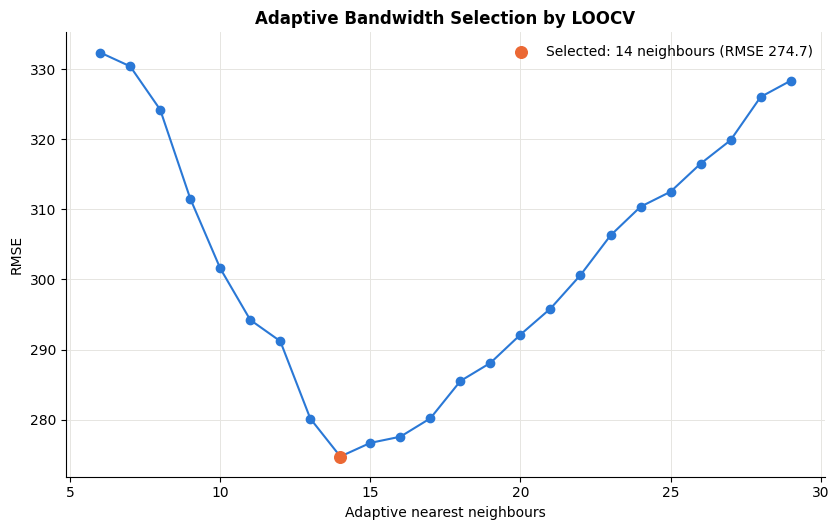

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
ax.plot(bandwidth_results["adaptive_neighbours"], bandwidth_results["loocv_rmse_sgd"], marker="o", color=BLUE)
ax.scatter(selected_row["adaptive_neighbours"], selected_row["loocv_rmse_sgd"], color=ORANGE, s=70, zorder=3,
           label=f"Selected: {selected_neighbours} neighbours (RMSE {selected_loocv_rmse:.1f})")
ax.set_title("Adaptive Bandwidth Selection by LOOCV", fontweight="bold")
ax.set_xlabel("Adaptive nearest neighbours")
ax.set_ylabel("RMSE")
ax.grid(color=GRID, linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "gwr_bandwidth_selection.png", dpi=240, bbox_inches="tight", facecolor="white")
plt.show()

## 4. Global OLS against GWR

The GWR fit statistics at the selected bandwidth next to the global OLS of 3.2 (in-sample R-squared,
RMSE, AICc, effective parameters). The AICc difference is the conventional yardstick: more than 4
favours the local model.

In [6]:
# 1. Global OLS on the same 30 areas, with its AICc on two parameters.
ols = ols_fit(income_thousands, outcome)
ols_sse = float(np.asarray(ols["residual"]) @ np.asarray(ols["residual"]))
ols_rmse = float(np.sqrt(ols_sse / len(data)))
_, ols_aicc = information_criteria(ols_sse, len(data), 2.0)
delta_aicc = ols_aicc - float(gwr["aicc"])
comparison = pd.DataFrame({
    "metric": ["R-squared", "RMSE (SGD)", "AICc", "effective parameters"],
    "global OLS": [ols["r_squared"], ols_rmse, ols_aicc, 2.0],
    "GWR": [gwr["r_squared"], gwr["rmse"], gwr["aicc"], gwr["trace_s"]],
})
print(comparison.round(3).to_string(index=False))
print(f"\nAICc(OLS) - AICc(GWR) = {delta_aicc:.1f}; GWR adjusted R-squared = {gwr['adjusted_r_squared']:.3f}; "
      f"effective residual df = {gwr['effective_df']:.2f}")

              metric  global OLS     GWR
           R-squared       0.626   0.861
          RMSE (SGD)     340.723 207.394
                AICc     439.445 429.217
effective parameters       2.000   8.287

AICc(OLS) - AICc(GWR) = 10.2; GWR adjusted R-squared = 0.806; effective residual df = 19.24


## 5. Local coefficients and t-tests

Each area's local intercept and income slope with an approximate t-test on the effective residual
degrees of freedom, and the Benjamini-Hochberg correction across the 30 slope tests. These tests ask
whether each local slope differs from zero, not whether the slopes differ from each other (section 6).

In [7]:
coefficients = np.asarray(gwr["coefficients"])
standard_errors = np.asarray(gwr["standard_errors"])
t_values = np.asarray(gwr["t_values"])
data["local_intercept_sgd"] = coefficients[:, 0]
data["local_income_slope_sgd_per_1000"] = coefficients[:, 1]
data["local_intercept_se"] = standard_errors[:, 0]
data["local_income_slope_se"] = standard_errors[:, 1]
data["local_intercept_t"] = t_values[:, 0]
data["local_income_slope_t"] = t_values[:, 1]
inference_df = float(gwr["effective_df"])
data["local_inference_effective_df"] = inference_df
data["local_intercept_p_two_sided"] = 2 * student_t.sf(np.abs(data["local_intercept_t"].to_numpy(dtype=float)), inference_df)
data["local_income_slope_p_two_sided"] = 2 * student_t.sf(np.abs(data["local_income_slope_t"].to_numpy(dtype=float)), inference_df)
data["local_intercept_p_fdr_bh"] = benjamini_hochberg(data["local_intercept_p_two_sided"].to_numpy(dtype=float))
data["local_income_slope_p_fdr_bh"] = benjamini_hochberg(data["local_income_slope_p_two_sided"].to_numpy(dtype=float))
data["local_intercept_significant_fdr_0_05"] = data["local_intercept_p_fdr_bh"] <= 0.05
data["local_income_slope_significant_fdr_0_05"] = data["local_income_slope_p_fdr_bh"] <= 0.05
data["local_r_squared"] = np.asarray(gwr["local_r2"])
data["gwr_fitted_fee_sgd"] = np.asarray(gwr["fitted"])
data["gwr_residual_sgd"] = np.asarray(gwr["residual"])
data["local_bandwidth_km"] = np.asarray(gwr["bandwidth_km"])
data["selected_adaptive_neighbours"] = selected_neighbours

slopes = data["local_income_slope_sgd_per_1000"]
print(f"local income slope: min {slopes.min():.1f}, median {slopes.median():.1f}, max {slopes.max():.1f} S$ per S$1,000; "
      f"positive in {int((slopes > 0).sum())} of {len(slopes)} areas")
print(f"slopes with p <= 0.05: {int((data['local_income_slope_p_two_sided'] <= 0.05).sum())}; "
      f"after FDR: {int(data['local_income_slope_significant_fdr_0_05'].sum())}; "
      f"intercepts significant after FDR: {int(data['local_intercept_significant_fdr_0_05'].sum())}")
print(data[["planning_area_name", "local_income_slope_sgd_per_1000", "local_income_slope_se", "local_income_slope_t",
            "local_income_slope_p_fdr_bh", "local_r_squared", "local_bandwidth_km"]]
      .sort_values("local_income_slope_sgd_per_1000", ascending=False).round(3).to_string(index=False))

local income slope: min 6.4, median 103.9, max 157.5 S$ per S$1,000; positive in 30 of 30 areas
slopes with p <= 0.05: 21; after FDR: 20; intercepts significant after FDR: 0
planning_area_name  local_income_slope_sgd_per_1000  local_income_slope_se  local_income_slope_t  local_income_slope_p_fdr_bh  local_r_squared  local_bandwidth_km
           Geylang                          157.503                 23.002                 6.847                        0.000            0.641               8.124
     Marine Parade                          150.563                 21.594                 6.973                        0.000            0.702               8.802
             Bedok                          132.366                 40.677                 3.254                        0.006            0.252              10.634
     Bukit Panjang                          121.973                 22.020                 5.539                        0.000            0.853              10.192
         To

## 6. Monte Carlo test of spatial variability (stationarity)

H0: the coefficient is spatially stationary; the spread of the local coefficients is no larger than
after randomly reassigning the areas' locations. H1: the local coefficients vary more than that. The
observed coordinates are permuted 999 times, GWR is refitted at the selected bandwidth each time, and
the across-area standard deviation of the coefficients is compared with the null distribution
(upper tail, plus-one correction). This is the test of whether a local model is needed at all.

In [8]:
def monte_carlo_spatial_variability(design, outcome, distance_matrix, neighbour_count, observed_coefficients,
                                    permutations, seed):
    """Upper-tail pseudo p for the SD of each local coefficient under random coordinate assignment."""
    parameter_names = ["intercept", "income_slope"]
    observed_sd = np.std(observed_coefficients, axis=0, ddof=1)
    permuted_sd = np.empty((permutations, observed_coefficients.shape[1]))
    rng = np.random.default_rng(seed)
    n = len(outcome)
    for iteration in range(permutations):
        coordinate_order = rng.permutation(n)
        randomised_distances = distance_matrix[np.ix_(coordinate_order, coordinate_order)]
        randomised_model = fit_gwr(design, outcome, randomised_distances, neighbour_count)
        permuted_sd[iteration] = np.std(np.asarray(randomised_model["coefficients"]), axis=0, ddof=1)
    rows = []
    for column, parameter in enumerate(parameter_names):
        extreme = int(np.count_nonzero(permuted_sd[:, column] >= observed_sd[column]))
        p_value = float((extreme + 1) / (permutations + 1))
        rows.append({
            "parameter": parameter, "observed_coefficient_sd": observed_sd[column],
            "null_mean_coefficient_sd": float(permuted_sd[:, column].mean()),
            "null_sd_coefficient_sd": float(permuted_sd[:, column].std(ddof=1)),
            "null_95th_percentile": float(np.quantile(permuted_sd[:, column], 0.95)),
            "extreme_permutations": extreme, "permutations": permutations, "pseudo_p_value_upper": p_value,
            "monte_carlo_se": math.sqrt(p_value * (1.0 - p_value) / (permutations + 1)),
            "significant_at_0_05": p_value <= 0.05, "selected_adaptive_neighbours": neighbour_count, "seed": seed,
        })
    distribution = pd.DataFrame({"permutation": np.arange(1, permutations + 1),
                                 "intercept_coefficient_sd": permuted_sd[:, 0],
                                 "income_slope_coefficient_sd": permuted_sd[:, 1]})
    return pd.DataFrame(rows), distribution


# 1. 999 coordinate randomisations at the selected bandwidth (seed 4017, as in the script).
spatial_variability, spatial_variability_distribution = monte_carlo_spatial_variability(
    design, outcome, distances, selected_neighbours, coefficients, PERMUTATIONS, SEED + 2)
print(spatial_variability[["parameter", "observed_coefficient_sd", "null_mean_coefficient_sd", "null_95th_percentile",
                           "pseudo_p_value_upper", "significant_at_0_05"]].round(3).to_string(index=False))
slope_variability = spatial_variability.loc[spatial_variability["parameter"].eq("income_slope")].iloc[0]
intercept_variability = spatial_variability.loc[spatial_variability["parameter"].eq("intercept")].iloc[0]
print(f"\nincome-slope stationarity: pseudo-p = {slope_variability['pseudo_p_value_upper']:.3f} -> "
      f"{'reject' if slope_variability['significant_at_0_05'] else 'fail to reject'} H0 (stationary) at 5%")

   parameter  observed_coefficient_sd  null_mean_coefficient_sd  null_95th_percentile  pseudo_p_value_upper  significant_at_0_05
   intercept                  278.621                   301.734               470.926                 0.560                False
income_slope                   41.982                    37.386                63.095                 0.345                False

income-slope stationarity: pseudo-p = 0.345 -> fail to reject H0 (stationary) at 5%


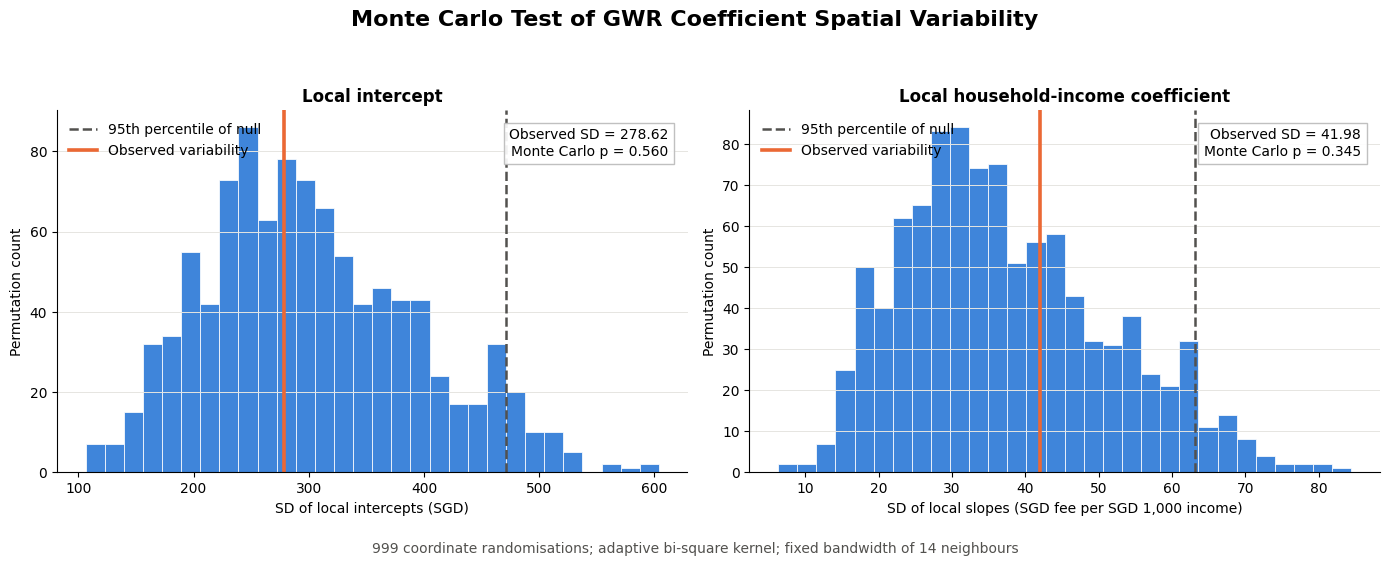

In [9]:
panels = [("intercept", "intercept_coefficient_sd", "Local intercept", "SD of local intercepts (SGD)"),
          ("income_slope", "income_slope_coefficient_sd", "Local household-income coefficient",
           "SD of local slopes (SGD fee per SGD 1,000 income)")]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for axis, (parameter, column, title, xlabel) in zip(axes, panels):
    row = spatial_variability.loc[spatial_variability["parameter"].eq(parameter)].iloc[0]
    axis.hist(spatial_variability_distribution[column].to_numpy(dtype=float), bins=30, color=BLUE,
              edgecolor="white", linewidth=0.6, alpha=0.9)
    axis.axvline(row["null_95th_percentile"], color=INK2, linestyle="--", linewidth=1.8, label="95th percentile of null")
    axis.axvline(row["observed_coefficient_sd"], color=ORANGE, linewidth=2.6, label="Observed variability")
    axis.set_title(title, fontweight="bold")
    axis.set_xlabel(xlabel)
    axis.set_ylabel("Permutation count")
    axis.text(0.97, 0.95, f"Observed SD = {row['observed_coefficient_sd']:.2f}\nMonte Carlo p = {row['pseudo_p_value_upper']:.3f}",
              transform=axis.transAxes, ha="right", va="top",
              bbox={"facecolor": "white", "edgecolor": "#BBBBBB", "alpha": 0.92})
    axis.grid(axis="y", color=GRID, linewidth=0.7)
    axis.spines[["top", "right"]].set_visible(False)
    axis.legend(frameon=False, loc="upper left")
fig.suptitle("Monte Carlo Test of GWR Coefficient Spatial Variability", fontsize=16, fontweight="bold")
fig.text(0.5, 0.01, f"{PERMUTATIONS:,} coordinate randomisations; adaptive bi-square kernel; fixed bandwidth of "
         f"{selected_neighbours} neighbours", ha="center", fontsize=10, color=INK2)
fig.tight_layout(rect=(0, 0.05, 1, 0.93))
fig.savefig(OUT_DIR / "gwr_monte_carlo_spatial_variability.png", dpi=240, bbox_inches="tight", facecolor="white")
plt.show()

## 7. Residual spatial autocorrelation

Moran's I of the OLS residuals and of the GWR residuals on the KNN-4 graph of planning-area centroids
(same weights as 3.1). If GWR has absorbed the spatial structure, its residual I should be near zero.

In [10]:
def residual_moran_test(residuals, coordinates_lonlat, permutations, seed):
    """Global Moran's I of residuals on a symmetric KNN-4 graph with a permutation pseudo p-value."""
    _, weights = knn_weights(coordinates_lonlat, k=min(4, len(residuals) - 1))
    z = (residuals - residuals.mean()) / residuals.std(ddof=0)
    observed = moran_i(z, weights)
    rng = np.random.default_rng(seed)
    permuted = np.empty(permutations)
    for index in range(permutations):
        permuted[index] = moran_i(rng.permutation(z), weights)
    expected = -1 / (len(z) - 1)
    extreme = np.count_nonzero(permuted >= observed) if observed >= expected else np.count_nonzero(permuted <= observed)
    return observed, float((extreme + 1) / (permutations + 1))


ols_residual_moran = residual_moran_test(np.asarray(ols["residual"]), lonlat, PERMUTATIONS, SEED)
gwr_residual_moran = residual_moran_test(np.asarray(gwr["residual"]), lonlat, PERMUTATIONS, SEED + 1)
print(f"OLS residual Moran's I = {ols_residual_moran[0]:.3f} (p = {ols_residual_moran[1]:.3f})")
print(f"GWR residual Moran's I = {gwr_residual_moran[0]:.3f} (p = {gwr_residual_moran[1]:.3f})")

OLS residual Moran's I = 0.275 (p = 0.009)
GWR residual Moran's I = -0.213 (p = 0.035)


## 8. Maps and local lines

Observed, fitted and residual fee surfaces (blues for the fee, a diverging scale for the residual) and
the 30 local regression lines over the global OLS line.

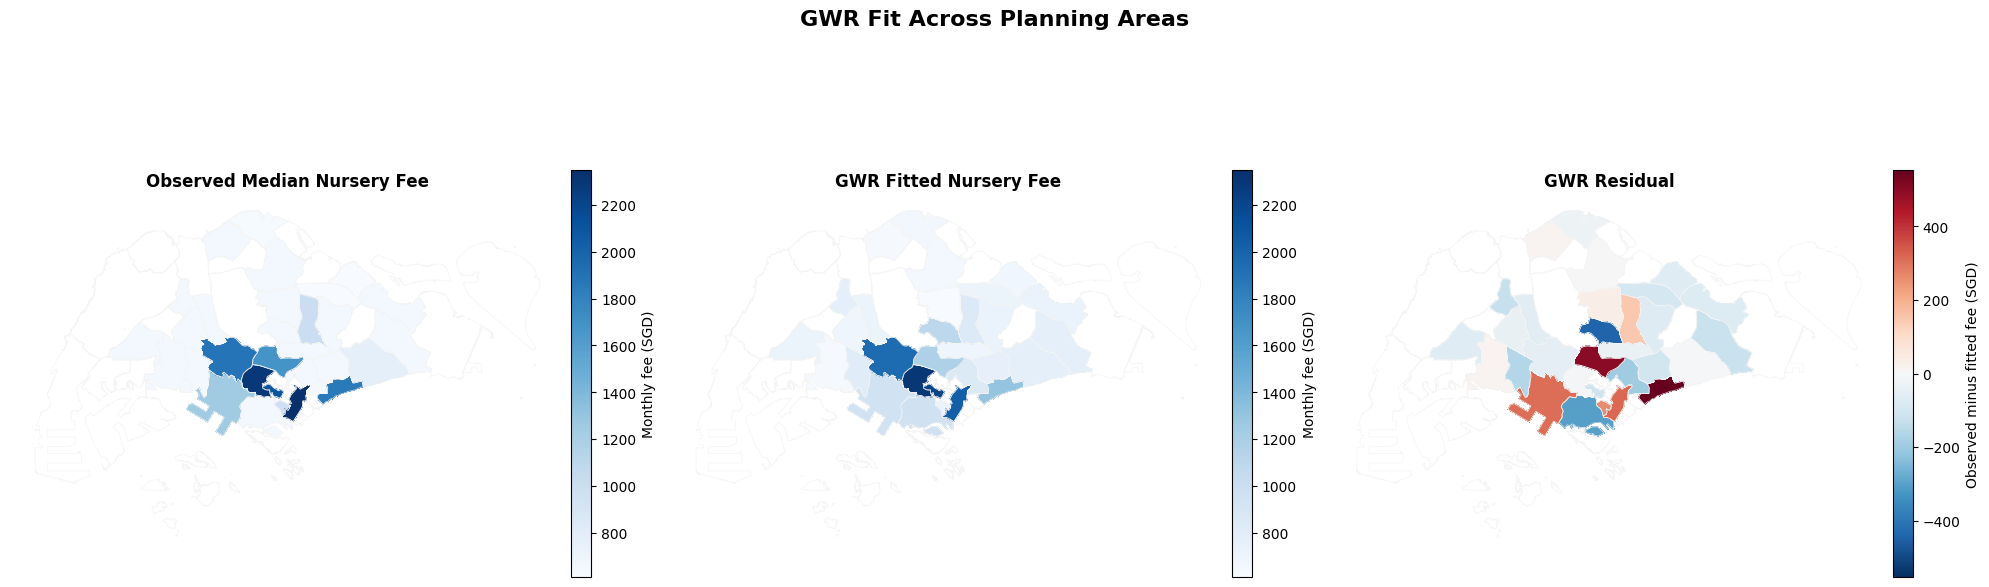

In [11]:
def draw_continuous_map(ax, fig, subzones, values_by_area, title, colourbar_label, cmap, norm,
                        colourbar_fraction=0.035, colourbar_shrink=1.0):
    """Planning-area choropleth from a name -> value dict with a colour bar."""
    patches, values = feature_patches(subzones, values_by_area)
    collection = matplotlib.collections.PatchCollection(patches, cmap=cmap, norm=norm, edgecolor="none",
                                                        linewidth=0, antialiased=False)
    collection.set_array(np.ma.masked_invalid(values))
    ax.add_collection(collection)
    add_planning_area_boundaries(ax, subzones)
    ax.autoscale_view()
    set_map_style(ax)
    ax.set_title(title, fontweight="bold")
    colourbar = fig.colorbar(collection, ax=ax, fraction=colourbar_fraction, shrink=colourbar_shrink, pad=0.01)
    colourbar.set_label(colourbar_label)


observed = data["median_fee_sgd"].to_numpy()
fitted = data["gwr_fitted_fee_sgd"].to_numpy()
residual = data["gwr_residual_sgd"].to_numpy()
fee_norm = Normalize(vmin=float(min(observed.min(), fitted.min())), vmax=float(max(observed.max(), fitted.max())))
residual_extent = max(abs(float(residual.min())), abs(float(residual.max())))
residual_norm = TwoSlopeNorm(vmin=-residual_extent, vcenter=0, vmax=residual_extent)
fig, axes = plt.subplots(1, 3, figsize=(20, 6.8))
for axis, column, title in zip(axes[:2], ["median_fee_sgd", "gwr_fitted_fee_sgd"],
                               ["Observed Median Nursery Fee", "GWR Fitted Nursery Fee"]):
    draw_continuous_map(axis, fig, subzones, dict(zip(data["planning_area"], data[column])), title,
                        "Monthly fee (SGD)", cmap="Blues", norm=fee_norm)   # changed 2026-11-10: single-hue blues
draw_continuous_map(axes[2], fig, subzones, dict(zip(data["planning_area"], residual)), "GWR Residual",
                    "Observed minus fitted fee (SGD)", cmap="RdBu_r", norm=residual_norm)
fig.suptitle("GWR Fit Across Planning Areas", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(OUT_DIR / "gwr_fit_maps.png", dpi=240, bbox_inches="tight", facecolor="white")
plt.show()

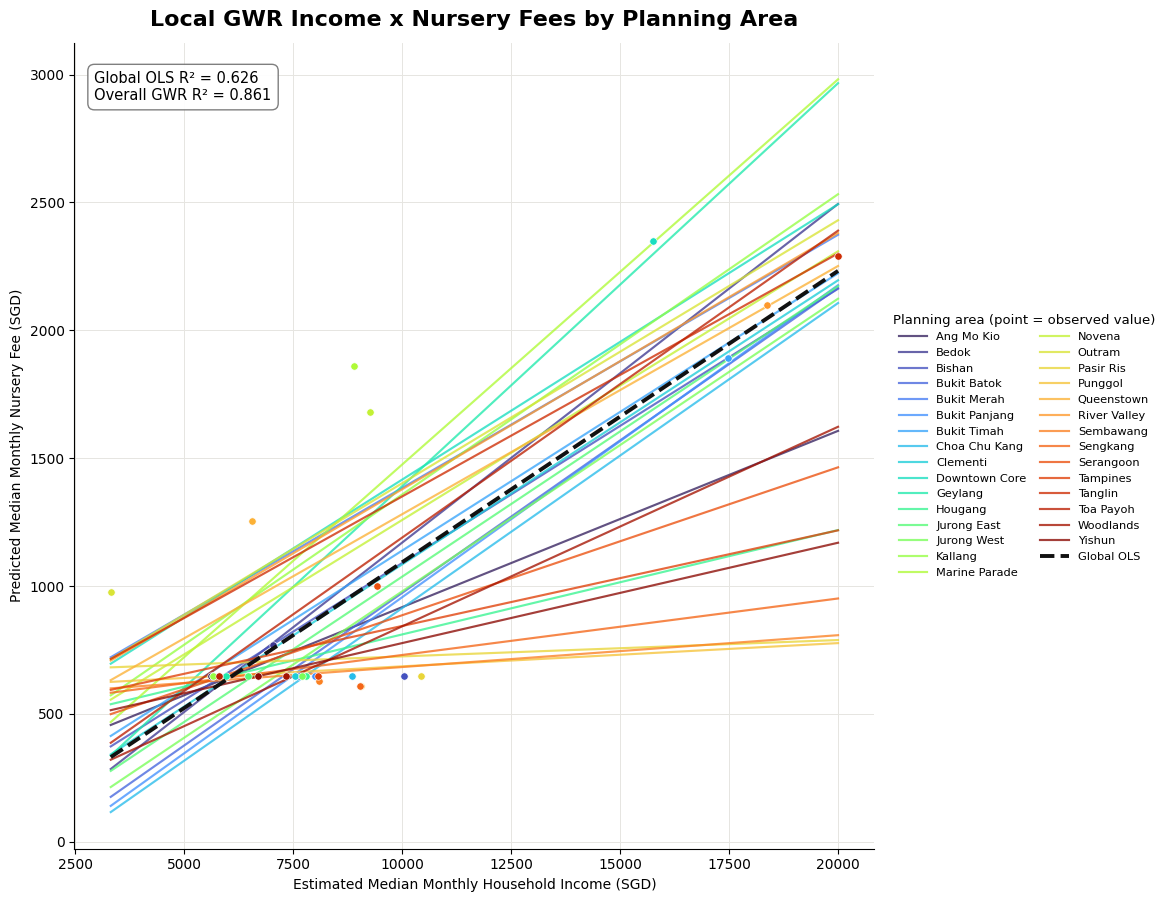

In [12]:
income = data["estimated_median_income_sgd"].to_numpy(dtype=float)
fee = data["median_fee_sgd"].to_numpy(dtype=float)
income_grid = np.linspace(float(income.min()), float(income.max()), 250)
income_grid_thousands = income_grid / 1_000
gwr_residual = fee - data["gwr_fitted_fee_sgd"].to_numpy(dtype=float)
gwr_r_squared = 1 - float(gwr_residual @ gwr_residual) / float(((fee - fee.mean()) ** 2).sum())
ordered = data.sort_values("planning_area_name").reset_index(drop=True)
colours = plt.colormaps["turbo"](np.linspace(0.02, 0.98, len(ordered)))   # 30 categories: palette too short
fig, ax = plt.subplots(figsize=(16, 9.5))
for colour, row in zip(colours, ordered.itertuples()):
    local_line = row.local_intercept_sgd + row.local_income_slope_sgd_per_1000 * income_grid_thousands
    ax.plot(income_grid, local_line, color=colour, linewidth=1.55, alpha=0.78, label=row.planning_area_name)
    ax.scatter(row.estimated_median_income_sgd, row.median_fee_sgd, s=28, color=colour, edgecolor="white",
               linewidth=0.45, zorder=3)
ax.plot(income_grid, float(ols["intercept"]) + float(ols["slope"]) * income_grid_thousands, color="#111111",
        linewidth=2.8, linestyle="--", label="Global OLS", zorder=4)
ax.set_title("Local GWR Income x Nursery Fees by Planning Area", fontsize=16, fontweight="bold", pad=12)
ax.set_xlabel("Estimated Median Monthly Household Income (SGD)")
ax.set_ylabel("Predicted Median Monthly Nursery Fee (SGD)")
ax.grid(color=GRID, linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.text(0.025, 0.965, f"Global OLS R\N{SUPERSCRIPT TWO} = {float(ols['r_squared']):.3f}\n"
        f"Overall GWR R\N{SUPERSCRIPT TWO} = {gwr_r_squared:.3f}", transform=ax.transAxes, ha="left", va="top",
        fontsize=10.5, bbox={"boxstyle": "round,pad=0.45", "facecolor": "white", "edgecolor": "#777777", "alpha": 0.94},
        zorder=6)
ax.legend(title="Planning area (point = observed value)", loc="center left", bbox_to_anchor=(1.01, 0.5), ncol=2,
          frameon=False, fontsize=8.2, title_fontsize=9.5, handlelength=2.5, columnspacing=1.2)
fig.tight_layout(rect=(0.04, 0.04, 0.78, 1))
fig.savefig(OUT_DIR / "gwr_local_regression_lines.png", dpi=240, bbox_inches="tight", facecolor="white")
plt.show()

## 9. Write the tables and the summary

In [13]:
data.to_csv(OUT_DIR / "gwr_local_results.csv", index=False)
bandwidth_results.to_csv(OUT_DIR / "gwr_bandwidth_selection.csv", index=False)
spatial_variability.to_csv(OUT_DIR / "gwr_monte_carlo_spatial_variability.csv", index=False)
spatial_variability_distribution.to_csv(OUT_DIR / "gwr_monte_carlo_null_distribution.csv", index=False)
summary_rows = [
    ("matched_planning_areas", len(data)),
    ("selected_adaptive_neighbours", selected_neighbours),
    ("gwr_effective_parameters_trace_s", gwr["trace_s"]),
    ("gwr_inference_effective_df", gwr["effective_df"]),
    ("gwr_r_squared", gwr["r_squared"]),
    ("gwr_adjusted_r_squared", gwr["adjusted_r_squared"]),
    ("gwr_rmse_sgd", gwr["rmse"]),
    ("gwr_aic", gwr["aic"]),
    ("gwr_aicc", gwr["aicc"]),
    ("ols_r_squared", ols["r_squared"]),
    ("ols_rmse_sgd", ols_rmse),
    ("ols_aicc", ols_aicc),
    ("ols_residual_moran_i", ols_residual_moran[0]),
    ("ols_residual_moran_p", ols_residual_moran[1]),
    ("gwr_residual_moran_i", gwr_residual_moran[0]),
    ("gwr_residual_moran_p", gwr_residual_moran[1]),
    ("monte_carlo_income_slope_variability_sd", slope_variability["observed_coefficient_sd"]),
    ("monte_carlo_income_slope_variability_p", slope_variability["pseudo_p_value_upper"]),
    ("monte_carlo_intercept_variability_sd", intercept_variability["observed_coefficient_sd"]),
    ("monte_carlo_intercept_variability_p", intercept_variability["pseudo_p_value_upper"]),
    ("local_income_slopes_significant_raw_0_05", int((data["local_income_slope_p_two_sided"] <= 0.05).sum())),
    ("local_income_slopes_significant_fdr_bh_0_05", int(data["local_income_slope_significant_fdr_0_05"].sum())),
    ("local_intercepts_significant_fdr_bh_0_05", int(data["local_intercept_significant_fdr_0_05"].sum())),
]
model_summary = pd.DataFrame(summary_rows, columns=["metric", "value"])
model_summary.to_csv(OUT_DIR / "gwr_model_summary.csv", index=False)
print(model_summary.to_string(index=False))

                                     metric      value
                     matched_planning_areas  30.000000
               selected_adaptive_neighbours  14.000000
           gwr_effective_parameters_trace_s   8.286551
                 gwr_inference_effective_df  19.242431
                              gwr_r_squared   0.861423
                     gwr_adjusted_r_squared   0.805985
                               gwr_rmse_sgd 207.394365
                                    gwr_aic 421.786742
                                   gwr_aicc 429.217034
                              ols_r_squared   0.625978
                               ols_rmse_sgd 340.722645
                                   ols_aicc 439.444884
                       ols_residual_moran_i   0.274665
                       ols_residual_moran_p   0.009000
                       gwr_residual_moran_i  -0.213452
                       gwr_residual_moran_p   0.035000
    monte_carlo_income_slope_variability_sd  41.982285
     monte

In [14]:
local_p = data["local_income_slope_p_two_sided"]
local_p_fdr = data["local_income_slope_p_fdr_bh"]
improvement = 100 * (ols_rmse - float(gwr["rmse"])) / ols_rmse
best = data.nlargest(5, "local_income_slope_sgd_per_1000")
weakest = data.nsmallest(5, "local_income_slope_sgd_per_1000")
conclusion = ("strongly improves" if delta_aicc > 10 else "moderately improves" if delta_aicc > 4
              else "slightly improves" if delta_aicc > 2 else "does not clearly improve")


def variability_conclusion(row):
    return "reject H0" if bool(row["significant_at_0_05"]) else "fail to reject H0"


def rows(frame):
    return "\n".join(f"- {row.planning_area_name}: ${row.local_income_slope_sgd_per_1000:,.1f} per $1,000 income "
                     f"(local R-squared {row.local_r_squared:.3f})" for row in frame.itertuples())


summary = f"""# Geographically weighted regression: household income and nursery fees

## Model

- Observations: **{len(data)} planning areas** matched across the income and nursery-fee datasets (fees: canonical 2026 centre layer via 3.1).
- Outcome: median monthly full-day nursery fee (SGD).
- Predictor: estimated median monthly household income, expressed per SGD 1,000.
- Kernel: adaptive bi-square over planning-area centroids.
- Bandwidth selection: minimum leave-one-out cross-validation (LOOCV) RMSE; AICc is not used to choose the bandwidth.
- Selected bandwidth: **{selected_neighbours} nearest neighbours**, excluding the target area itself.
- Minimum leave-one-out RMSE: **{selected_loocv_rmse:.1f} SGD**.
- The model is descriptive; it does not establish that household income causes nursery fees.

## Global OLS versus GWR

| Metric | Global OLS | GWR |
| --- | ---: | ---: |
| R-squared | {float(ols['r_squared']):.3f} | {float(gwr['r_squared']):.3f} |
| RMSE (SGD) | {ols_rmse:.1f} | {float(gwr['rmse']):.1f} |
| AICc | {ols_aicc:.1f} | {float(gwr['aicc']):.1f} |
| Effective parameters | 2.0 | {float(gwr['trace_s']):.2f} |

The GWR model **{conclusion}** on global OLS by the conventional AICc comparison (OLS minus GWR = **{delta_aicc:.1f}**). Its in-sample RMSE is **{improvement:.1f}%** lower. Because GWR is more flexible, the AICc and leave-one-out results should be considered alongside the in-sample fit.

## Spatial variation in the income coefficient

- Local slope range: **${slopes.min():,.1f} to ${slopes.max():,.1f}** change in median fee per additional SGD 1,000 of median income.
- Median local slope: **${slopes.median():,.1f} per SGD 1,000**.
- Positive local slopes: **{int((slopes > 0).sum())} of {len(slopes)}** planning areas.
- Effective residual degrees of freedom used for approximate local t-tests: **{inference_df:.2f}**.
- Areas with unadjusted two-sided p <= 0.05: **{int((local_p <= 0.05).sum())}**.
- Areas remaining significant at 5% after Benjamini-Hochberg FDR correction across the {len(slopes)} income-slope tests: **{int((local_p_fdr <= 0.05).sum())}**.
- The smallest non-significant adjusted income-slope p-value is **{local_p_fdr[local_p_fdr > 0.05].min() if (local_p_fdr > 0.05).any() else float('nan'):.3f}**.

### Monte Carlo spatial-variability test

- H0: the coefficient is spatially stationary; its observed across-area variability is no greater than expected after randomly reassigning locations.
- H1: the coefficient exhibits greater spatial variability than expected under random location assignment.
- Method: **{int(slope_variability['permutations']):,} coordinate randomisations**, refitting GWR each time at the fixed, selected bandwidth of **{selected_neighbours} neighbours**. The test statistic is the sample standard deviation of the local coefficients, and the pseudo p-value uses the upper tail with the plus-one correction.

| Parameter | Observed SD | Null mean SD | Null 95th percentile | Pseudo p-value | Decision at 5% |
| --- | ---: | ---: | ---: | ---: | --- |
| Intercept | {intercept_variability['observed_coefficient_sd']:.2f} | {intercept_variability['null_mean_coefficient_sd']:.2f} | {intercept_variability['null_95th_percentile']:.2f} | {intercept_variability['pseudo_p_value_upper']:.3f} | {variability_conclusion(intercept_variability)} |
| Income slope | {slope_variability['observed_coefficient_sd']:.2f} | {slope_variability['null_mean_coefficient_sd']:.2f} | {slope_variability['null_95th_percentile']:.2f} | {slope_variability['pseudo_p_value_upper']:.3f} | {variability_conclusion(slope_variability)} |

The income-slope test is the primary test of the research hypothesis. Local t-values test whether individual coefficients differ from zero; they do **not** test whether the coefficient varies significantly across space.

Strongest local coefficients:

{rows(best)}

Weakest local coefficients:

{rows(weakest)}

## Residual spatial autocorrelation

- Global OLS residual Moran's I: **{ols_residual_moran[0]:.3f}**, permutation p = **{ols_residual_moran[1]:.3f}**.
- GWR residual Moran's I: **{gwr_residual_moran[0]:.3f}**, permutation p = **{gwr_residual_moran[1]:.3f}**.

## Limitations

There are only {len(data)} matched planning areas and one explanatory variable. Local estimates can therefore be sensitive to bandwidth choice, influential high-fee areas, and the grouped-income interpolation. The nursery fees are the October 2026 ECDA listing; the income CSV does not state its reference year. Provider type, subsidies, commercial rents, programme characteristics, and centre composition remain omitted variables. Interpret the coefficient surfaces as exploratory spatial heterogeneity rather than causal effects.
"""
(OUT_DIR / "gwr_analysis_summary.md").write_text(summary, encoding="utf-8")
print(f"written to {OUT_DIR.relative_to(ROOT)}/:")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name}")
print(f"\nHeadline: {selected_neighbours} neighbours by LOOCV; GWR R-squared {gwr['r_squared']:.3f} vs OLS {ols['r_squared']:.3f}; "
      f"income-slope stationarity p = {slope_variability['pseudo_p_value_upper']:.3f}")

written to output/gwr_income_nursery_fee_planning_area/:
  gwr_analysis_summary.md
  gwr_bandwidth_selection.csv
  gwr_bandwidth_selection.png
  gwr_fit_maps.png
  gwr_income_coefficient.png
  gwr_local_regression_lines.png
  gwr_local_results.csv
  gwr_model_summary.csv
  gwr_monte_carlo_null_distribution.csv
  gwr_monte_carlo_spatial_variability.csv
  gwr_monte_carlo_spatial_variability.png

Headline: 14 neighbours by LOOCV; GWR R-squared 0.861 vs OLS 0.626; income-slope stationarity p = 0.345
